# Week 4 – Consumer Complaint Trends and Response Intelligence
### Data Science track: exploratory analysis and statistical investigation

**Dataset:** CFPB consumer complaints about Bank of America, 1 May 2017 – 28 August 2023 (62,516 records)

**Research focus:** complaint trends, products and issues, recorded company responses, and CFPB complaint-forwarding intervals.

> A complaint is an issue *reported by a consumer*. It does not establish misconduct or prove that any regulation was broken. All findings below describe patterns in the recorded data only.

---
# 1. Business problem, research questions and definitions

**Business problem.** Stakeholders want a reliable, evidence-based picture of the complaints recorded against Bank of America: how volumes have moved, which products and issues dominate, how the company's responses are recorded, and how long the CFPB takes to forward complaints.

**Intended users:** complaint-monitoring, operations and compliance-review teams.
**Decision supported:** where to focus further review of complaint handling.
**Evidence limitation:** historical, observational, single-company data. It can show patterns and associations, not causes.

## 1.1 Which of the ten project questions this track answers

| # | Project question | Where answered |
|---|---|---|
| 1 | How have complaint volumes changed 2017–2023? | 5.1, 5.2 |
| 2 | Which products have the highest volumes? | 5.4 |
| 3 | What are the most frequently reported issues? | 5.5 |
| 4 | How do issues differ across product categories? | 5.6 |
| 5 | How long does the CFPB take to forward a complaint? | 5.10, 6.1 |
| 6 | Which company response categories are most frequent? | 5.7 |
| 7 | What percentage has a recorded timely response? | 5.8 |
| 8 | Have patterns and response categories changed over time? | 5.8, 5.9, 6.3 |
| 9 | Can history support volume forecasting? | **Not answered here** (Machine Learning track) |
| 10 | Dashboard / AI assistant access | **Not answered here** (Data Analytics and Generative AI tracks) |

## 1.2 Questions this dataset cannot answer
* **Whether complaints were justified**, or whether the company acted wrongly (no verification or narratives).
* **How long the company took to respond or resolve** (the only interval available is CFPB-to-company forwarding).
* **Whether a response resolved the consumer's problem** (a recorded category is not proof of satisfaction).
* **Complaint *rates*** (there is no customer, account or transaction denominator, so higher volume does not mean a worse product).
* **Why volumes rose or fell** (no information on causes).

## 1.3 Research questions and hypotheses (tested in Section 6)
* **H1.** Do CFPB forwarding intervals differ across financial product groups?
* **H2.** Is the recorded company response category associated with the product group?
* **H3.** Has the share of complaints with a recorded timely response changed across years?

## 1.4 Shared metric definitions (agreed across tracks)
| Term | Definition used in this notebook |
|---|---|
| Complaint volume | Number of rows (one row per Complaint ID), counted by **Date submitted** |
| Forwarding interval | `Date received` − `Date submitted`, in days. It is the CFPB-to-company interval, **not** the company's response or resolution time |
| Timely-response % | `Yes ÷ (Yes + No)`. Blank values (all "In progress") are excluded from the denominator and reported separately |
| Company response | The `Company response to consumer` category as recorded; not proof of resolution |
| Partial periods | 2017 (May–Dec) and 2023 (Jan–28 Aug) are partial years; August 2023 is a partial month |

---
# 2. Setup

In [1]:
import os, hashlib, json, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
SEED = 42                                        # one seed so every random step is repeatable
rng = np.random.default_rng(SEED)

DATA, PROC, FIG, TAB, REP = "data", "data/processed", "outputs/figures", "outputs/tables", "reports"
for folder in (PROC, FIG, TAB, REP):
    os.makedirs(folder, exist_ok=True)

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid")
BLUE, ORANGE, GREY, GREEN = "#1f6f8b", "#e07b39", "#8a8f94", "#4c9f70"
RESULTS = {}                                     # key numbers collected for the report
dq_log = []                                      # data-quality log: one row per check

def save_fig(name):
    plt.tight_layout(); plt.savefig(f"{FIG}/{name}", dpi=150, bbox_inches="tight"); plt.show(); plt.close()

def show_md(text): display(Markdown(text))
def fmt_p(p): return "< 0.001" if p < 0.001 else f"{p:.3f}"
def pct(x, d=1): return f"{x * 100:.{d}f}%"
def wrap(s, w=34): return "\n".join(textwrap.wrap(str(s), w))
def md5(path):
    with open(path, "rb") as fh: return hashlib.md5(fh.read()).hexdigest()
def log_dq(check, finding, meaning, action):
    dq_log.append({"check": check, "finding": finding, "what_it_means": meaning, "action_taken": action})

---
# 3. Inspect the data

The original file is **never modified**. Its fingerprint (MD5 hash) is recorded now and re-checked at the end (Section 8).
## 3.1 Load and look at the structure

In [2]:
RAW_FILE = f"{DATA}/Consumer_Complaints.csv"
raw_hash_before = md5(RAW_FILE)
raw = pd.read_csv(RAW_FILE)                                                   # original, left untouched
dictionary = pd.read_csv(f"{DATA}/ConsumerComplaints_DataDictionary.csv", encoding="utf-8-sig")

print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
display(pd.DataFrame({"dtype": raw.dtypes.astype(str), "distinct_values": raw.nunique()}))
display(raw.head(3))

Rows: 62,516 | Columns: 12


,dtype,distinct_values
Complaint ID,int64,62516
Submitted via,str,7
Date submitted,str,2308
Date received,str,2305
State,str,51
Product,str,9
Sub-product,str,46
Issue,str,76
Sub-issue,str,158
Company public response,str,6


,Complaint ID,Submitted via,Date submitted,Date received,State,Product,Sub-product,Issue,Sub-issue,Company public response,Company response to consumer,Timely response?
0,4848023,Referral,2021-10-24,2021-10-27,NY,Mortgage,Conventional home mortgage,Applying for a mortgage or refinancing an existing mortgage,NaN,Company has responded to the consumer and the CFPB and chooses not to provid...,Closed with explanation,Yes
1,3621464,Web,2020-04-24,2020-04-24,FL,"Money transfer, virtual currency, or money service",Refund anticipation check,Lost or stolen check,NaN,Company has responded to the consumer and the CFPB and chooses not to provid...,Closed with monetary relief,Yes
2,5818349,Web,2022-07-27,2022-07-27,CA,"Credit reporting, credit repair services, or other personal consumer reports",Credit reporting,Incorrect information on your report,Account information incorrect,Company has responded to the consumer and the CFPB and chooses not to provid...,Closed with explanation,Yes


Both date columns are stored as **text** and must be converted. Everything else is categorical text except `Complaint ID` (an integer identifier).

## 3.2 Does the data dictionary match the file?

In [3]:
dict_fields, file_cols = set(dictionary["Field"]), set(raw.columns)
print("In dictionary but not in file:", sorted(dict_fields - file_cols) or "none")
print("In file but not in dictionary:", sorted(file_cols - dict_fields) or "none")
log_dq("Dictionary vs file", "All 12 dictionary fields exist in the file and vice versa", "Field definitions can be relied on", "None needed")

In dictionary but not in file: none
In file but not in dictionary: none


## 3.3 Uniqueness and duplicates

In [4]:
n_dup_id = int(raw["Complaint ID"].duplicated().sum())
n_dup_row = int(raw.duplicated().sum())
n_dup_content = int(raw.drop(columns="Complaint ID").duplicated().sum())
print(f"Repeated Complaint IDs: {n_dup_id} | fully duplicated rows: {n_dup_row} | rows identical in every field except the ID: {n_dup_content:,}")
log_dq("Primary key", f"Complaint ID is unique ({n_dup_id} repeats)", "Complaint ID is a valid primary key; one row = one complaint", "None needed")
log_dq("Duplicates", f"{n_dup_row} fully duplicated rows; {n_dup_content:,} rows share every field except the ID", "Matching content with different IDs is most plausibly separate complaints, but a repeat consumer cannot be identified (no consumer ID)", "Nothing removed; noted as a limitation")

Repeated Complaint IDs: 0 | fully duplicated rows: 0 | rows identical in every field except the ID: 1,494


## 3.4 Missing values
Blank does not always mean *error*. We check what each blank is associated with before deciding what to do.

In [5]:
miss = raw.isna().sum().to_frame("missing"); miss["% of rows"] = (miss["missing"] / len(raw) * 100).round(2)
display(miss[miss["missing"] > 0])

print("\nTimely response? blank -> Company response to consumer:")
print(raw.loc[raw["Timely response?"].isna(), "Company response to consumer"].value_counts().to_string())

print("\nCompany public response blank -> Company response to consumer:")
print(raw.loc[raw["Company public response"].isna(), "Company response to consumer"].value_counts().to_string())

print("\nSub-issue blank, share by Product:")
print((raw.groupby("Product")["Sub-issue"].apply(lambda s: s.isna().mean()) * 100).round(0).sort_values(ascending=False).to_string())
print("\nSub-product blank rows by Product:", raw.loc[raw["Sub-product"].isna(), "Product"].value_counts().to_dict())

,missing,% of rows
Sub-product,7,0.01
Sub-issue,10858,17.37
Company public response,2175,3.48
Timely response?,1494,2.39



Timely response? blank -> Company response to consumer:
Company response to consumer
In progress    1494

Company public response blank -> Company response to consumer:
Company response to consumer
In progress                        1494
Closed with explanation             469
Closed with monetary relief         164
Closed with non-monetary relief      40
Closed                                8

Sub-issue blank, share by Product:
Product
Money transfer, virtual currency, or money service                              100.0
Mortgage                                                                         96.0
Payday loan, title loan, or personal loan                                        93.0
Credit card or prepaid card                                                       4.0
Credit reporting, credit repair services, or other personal consumer reports      2.0
Checking or savings account                                                       0.0
Debt collection                          

In [6]:
n_timely_na = int(raw["Timely response?"].isna().sum())
assert set(raw.loc[raw["Timely response?"].isna(), "Company response to consumer"]) == {"In progress"}   # brief's rule confirmed
log_dq("Missing: Timely response?", f"{n_timely_na:,} blanks, every one on a complaint marked 'In progress'", "Blank means 'no timeliness decision yet', NOT 'No'", "Kept blank; excluded from the timely-response denominator and reported separately")
log_dq("Missing: Sub-issue", f"{int(raw['Sub-issue'].isna().sum()):,} blanks ({raw['Sub-issue'].isna().mean():.1%}); near-total for Money transfer and Mortgage, none for several other products", "Mostly structural: some products simply have no sub-issues", "Labelled 'Not recorded / not applicable'; not filled in")
log_dq("Missing: Company public response", f"{int(raw['Company public response'].isna().sum()):,} blanks ({raw['Company public response'].isna().mean():.1%}), including all 'In progress' complaints", "The public response is optional; blank means none was posted", "Labelled 'Not provided'")
log_dq("Missing: Sub-product", f"{int(raw['Sub-product'].isna().sum())} blanks, all Checking or savings account", "Too few to matter", "Labelled 'Not recorded'")

## 3.5 Dates

In [7]:
d_sub = pd.to_datetime(raw["Date submitted"], format="%Y-%m-%d", errors="coerce")
d_rec = pd.to_datetime(raw["Date received"], format="%Y-%m-%d", errors="coerce")
interval = (d_rec - d_sub).dt.days
print(f"Unparseable dates: submitted={int(d_sub.isna().sum())}, received={int(d_rec.isna().sum())}")
print(f"Date submitted: {d_sub.min().date()} to {d_sub.max().date()} | Date received: {d_rec.min().date()} to {d_rec.max().date()}")
print(f"Negative intervals: {int((interval < 0).sum())} | same-day: {int((interval == 0).sum()):,} | over 30 days: {int((interval > 30).sum())} | maximum: {int(interval.max())} days")
log_dq("Dates", f"All dates parse; range {d_sub.min().date()} to {d_sub.max().date()}; {int((interval < 0).sum())} negative intervals", "Date logic is consistent (received is never before submitted)", "Converted to datetime; 2017, 2023 and Aug-2023 flagged as partial periods")
log_dq("Forwarding interval", f"Median {interval.median():.0f} day(s), maximum {int(interval.max())}; {int((interval > 30).sum())} intervals over 30 days", "Highly skewed; a few very long intervals", "Kept and flagged (not deleted); reported with medians and shares")

Unparseable dates: submitted=0, received=0
Date submitted: 2017-05-01 to 2023-08-28 | Date received: 2017-05-01 to 2023-08-28
Negative intervals: 0 | same-day: 49,634 | over 30 days: 435 | maximum: 275 days


## 3.6 Categories: spelling, case and unusual values

In [8]:
cat_cols = ["Submitted via", "Product", "Sub-product", "Issue", "Sub-issue", "Company public response", "Company response to consumer", "Timely response?", "State"]
rows = []
for c in cat_cols:
    s = raw[c].dropna()
    rows.append((c, s.nunique(), s.str.strip().str.lower().nunique(), int((s != s.str.strip()).sum())))
display(pd.DataFrame(rows, columns=["column", "distinct", "distinct_after_trim_and_lowercase", "values_with_stray_spaces"]))
for c in ["Submitted via", "Company response to consumer", "Timely response?", "Product"]:
    print(f"\n{c}"); print(raw[c].value_counts(dropna=False).to_string())
print("\nStates:", raw["State"].nunique(), "distinct values (50 states + DC)")

,column,distinct,distinct_after_trim_and_lowercase,values_with_stray_spaces
0,Submitted via,7,7,0
1,Product,9,9,0
2,Sub-product,46,46,0
3,Issue,76,76,0
4,Sub-issue,158,158,0
5,Company public response,6,6,0
6,Company response to consumer,5,5,0
7,Timely response?,2,2,0
8,State,51,51,0



Submitted via
Submitted via
Web             45423
Referral        10766
Phone            4684
Postal mail      1318
Fax               233
Web Referral       90
Email               2

Company response to consumer
Company response to consumer
Closed with explanation            41044
Closed with monetary relief        14697
Closed with non-monetary relief     5273
In progress                         1494
Closed                                 8

Timely response?
Timely response?
Yes    58619
No      2403
NaN     1494

Product
Product
Checking or savings account                                                     24814
Credit card or prepaid card                                                     16197
Credit reporting, credit repair services, or other personal consumer reports     7710
Mortgage                                                                         6601
Money transfer, virtual currency, or money service                               3453
Debt collection                 

In [9]:
log_dq("Categories: spelling and case", "No spelling, case or spacing variants found in any categorical column", "Category labels are already consistent", "No re-spelling needed")
log_dq("Unusual: 'Web Referral'", f"{int((raw['Submitted via'] == 'Web Referral').sum())} records labelled 'Web Referral' beside {int((raw['Submitted via'] == 'Referral').sum()):,} 'Referral'", "Probably the same channel under two labels, but the dictionary does not say", "Original kept; a grouped `channel_group` merges them for channel comparisons (assumption)")
log_dq("Unusual: response 'Closed'", f"{int((raw['Company response to consumer'] == 'Closed').sum())} records have the bare label 'Closed' (no explanation or relief detail)", "Cannot be assigned to any other closed category without guessing", "Kept in descriptive counts; excluded from H2 and reported")
log_dq("Product detail", "Product has 9 categories; the 3 smallest are Student loan (39), Payday/title/personal loan (333) and Vehicle loan or lease (633)", "Small groups have unstable percentages and violate chi-square expected-count rules", "Described individually; combined into one group for hypothesis tests")

---
# 4. Prepare the analysis dataset
All 62,516 rows are kept. Nothing is deleted and no missing value is invented; blanks get an explicit label, and unusual values are **flagged**.

In [10]:
df = raw.rename(columns={
    "Complaint ID": "complaint_id", "Submitted via": "submitted_via", "Date submitted": "date_submitted",
    "Date received": "date_received", "State": "state", "Product": "product", "Sub-product": "sub_product",
    "Issue": "issue", "Sub-issue": "sub_issue", "Company public response": "public_response",
    "Company response to consumer": "company_response", "Timely response?": "timely_response"}).copy()

# dates and time fields
df["date_submitted"] = pd.to_datetime(df["date_submitted"], format="%Y-%m-%d")
df["date_received"] = pd.to_datetime(df["date_received"], format="%Y-%m-%d")
df["interval_days"] = (df["date_received"] - df["date_submitted"]).dt.days
df["year"] = df["date_submitted"].dt.year
df["month"] = df["date_submitted"].dt.month
df["quarter"] = df["date_submitted"].dt.quarter
df["year_month"] = df["date_submitted"].dt.to_period("M")
df["year_quarter"] = df["date_submitted"].dt.to_period("Q")
PARTIAL_YEARS = [2017, 2023]

# explicit labels for blanks (original columns are not touched; timely_response stays blank on purpose)
df["sub_issue"] = df["sub_issue"].fillna("Not recorded / not applicable")
df["public_response"] = df["public_response"].fillna("Not provided")
df["sub_product"] = df["sub_product"].fillna("Not recorded")

# grouped / display versions
df["channel_group"] = df["submitted_via"].replace({"Web Referral": "Referral", "Fax": "Fax or email", "Email": "Fax or email"})
product_short = {
    "Checking or savings account": "Checking or savings account", "Credit card or prepaid card": "Credit card or prepaid card",
    "Credit reporting, credit repair services, or other personal consumer reports": "Credit reporting and repair",
    "Mortgage": "Mortgage", "Money transfer, virtual currency, or money service": "Money transfer / virtual currency",
    "Debt collection": "Debt collection", "Vehicle loan or lease": "Vehicle loan or lease",
    "Payday loan, title loan, or personal loan": "Payday, title or personal loan", "Student loan": "Student loan"}
df["product_short"] = df["product"].map(product_short)
small_products = ["Vehicle loan or lease", "Payday, title or personal loan", "Student loan"]
df["product_group"] = df["product_short"].where(~df["product_short"].isin(small_products), "Vehicle, payday and student loans")

# forwarding-interval bands and flags
bands = ["Same day", "1 day", "2–3 days", "4–7 days", "8–30 days", "Over 30 days"]
df["interval_band"] = pd.cut(df["interval_days"], bins=[-1, 0, 1, 3, 7, 30, np.inf], labels=bands)
df["long_interval_flag"] = df["interval_days"] > 30
df["in_progress_flag"] = df["company_response"] == "In progress"
df["timely_valid"] = df["timely_response"].isin(["Yes", "No"])

df.to_csv(f"{PROC}/complaints_clean.csv", index=False)
print(f"Prepared dataset: {df.shape[0]:,} rows x {df.shape[1]} columns (saved to {PROC}/complaints_clean.csv)")
print("New fields: year, month, quarter, year_month, year_quarter, interval_days, interval_band, long_interval_flag, in_progress_flag, timely_valid, channel_group, product_short, product_group")

Prepared dataset: 62,516 rows x 25 columns (saved to data/processed/complaints_clean.csv)
New fields: year, month, quarter, year_month, year_quarter, interval_days, interval_band, long_interval_flag, in_progress_flag, timely_valid, channel_group, product_short, product_group


In [11]:
assert len(df) == len(raw) == 62516, "rows changed during preparation"
n_before = len(raw)
RESULTS.update({"n_complaints": int(len(df)), "date_min": str(df["date_submitted"].min().date()), "date_max": str(df["date_submitted"].max().date()),
                "n_products": int(df["product"].nunique()), "n_issues": int(df["issue"].nunique()), "n_states": int(df["state"].nunique())})
log_dq("Preparation", f"All {n_before:,} rows retained; 13 derived fields added (year, month, quarter, interval, bands, flags, groups)", "No information lost; original columns unchanged", "Cleaned copy saved separately; original file preserved")

dq_df = pd.DataFrame(dq_log)
display(dq_df)
dq_df.to_csv(f"{TAB}/data_quality_summary.csv", index=False)
with open(f"{REP}/Data_Quality_Summary.md", "w", encoding="utf-8") as fh:
    fh.write("# Data-Quality Summary: Bank of America Consumer Complaints (Week 4, Data Science track)\n\n")
    fh.write("Generated by the analysis notebook. Source: CFPB Consumer Complaint records, 1 May 2017 to 28 August 2023.\n\n")
    fh.write(f"**Rows:** {len(raw):,} | **Columns:** {raw.shape[1]} (flat file, one row per complaint)\n\n")
    fh.write("## Checks, findings and decisions\n\n| Check | Finding | What it means | Action taken |\n|---|---|---|---|\n")
    for _, r in dq_df.iterrows():
        fh.write(f"| {r['check']} | {r['finding']} | {r['what_it_means']} | {r['action_taken']} |\n")
    fh.write("\n**Principle applied:** no row was deleted and no missing value was invented. Blanks received explicit labels, and unusual values were flagged and tested rather than removed. The original data file is unchanged (hash verified in the notebook).\n")
print("Saved: reports/Data_Quality_Summary.md")

,check,finding,what_it_means,action_taken
0,Dictionary vs file,All 12 dictionary fields exist in the file and vice versa,Field definitions can be relied on,None needed
1,Primary key,Complaint ID is unique (0 repeats),Complaint ID is a valid primary key; one row = one complaint,None needed
2,Duplicates,"0 fully duplicated rows; 1,494 rows share every field except the ID","Matching content with different IDs is most plausibly separate complaints, b...",Nothing removed; noted as a limitation
3,Missing: Timely response?,"1,494 blanks, every one on a complaint marked 'In progress'","Blank means 'no timeliness decision yet', NOT 'No'",Kept blank; excluded from the timely-response denominator and reported separ...
4,Missing: Sub-issue,"10,858 blanks (17.4%); near-total for Money transfer and Mortgage, none for ...",Mostly structural: some products simply have no sub-issues,Labelled 'Not recorded / not applicable'; not filled in
5,Missing: Company public response,"2,175 blanks (3.5%), including all 'In progress' complaints",The public response is optional; blank means none was posted,Labelled 'Not provided'
6,Missing: Sub-product,"7 blanks, all Checking or savings account",Too few to matter,Labelled 'Not recorded'
7,Dates,All dates parse; range 2017-05-01 to 2023-08-28; 0 negative intervals,Date logic is consistent (received is never before submitted),"Converted to datetime; 2017, 2023 and Aug-2023 flagged as partial periods"
8,Forwarding interval,"Median 0 day(s), maximum 275; 435 intervals over 30 days",Highly skewed; a few very long intervals,Kept and flagged (not deleted); reported with medians and shares
9,Categories: spelling and case,"No spelling, case or spacing variants found in any categorical column",Category labels are already consistent,No re-spelling needed


Saved: reports/Data_Quality_Summary.md


---
# 5. Exploratory data analysis
Each chart is followed by what it **shows** and what it **cannot show**.

## 5.1 Annual complaint volume
2017 (May–Dec) and 2023 (Jan–28 Aug) are partial years, so their raw totals cannot be compared with full years. The right-hand chart therefore compares the **same window in every year (1 January – 28 August)**, which is like-for-like for 2018–2023.

,complaints,share_of_total_%,yoy_change_%,period,jan_to_28aug,jan_to_28aug_yoy_%
year,,,,,,
2017,5394,8.6,NaN,partial (May-Dec),NaN,NaN
2018,7872,12.6,45.9,full,5576.0,NaN
2019,7075,11.3,-10.1,full,4472.0,-19.8
2020,8942,14.3,26.4,full,5391.0,20.6
2021,11149,17.8,24.7,full,7506.0,39.2
2022,12953,20.7,16.2,full,8201.0,9.3
2023,9131,14.6,-29.5,partial (Jan-28 Aug),9131.0,11.3


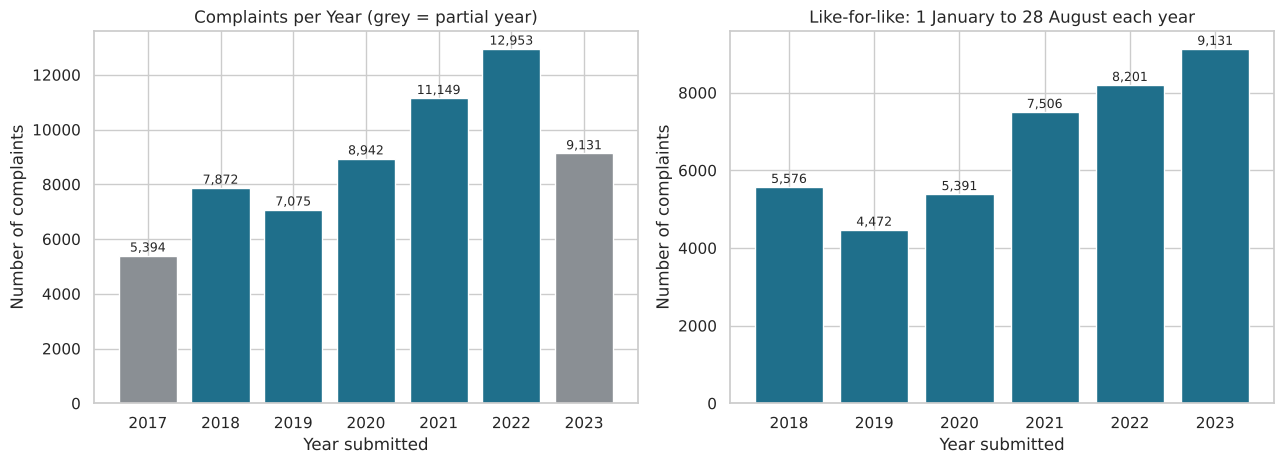

In [12]:
annual = df.groupby("year").size().to_frame("complaints")
annual["share_of_total_%"] = (annual["complaints"] / len(df) * 100).round(1)
annual["yoy_change_%"] = (annual["complaints"].pct_change() * 100).round(1)
annual["period"] = ["partial (May-Dec)"] + ["full"] * 5 + ["partial (Jan-28 Aug)"]

like = (df["month"] < 8) | ((df["month"] == 8) & (df["date_submitted"].dt.day <= 28))      # 1 Jan - 28 Aug
janaug = df[like & (df["year"] >= 2018)].groupby("year").size()
annual["jan_to_28aug"] = janaug
annual["jan_to_28aug_yoy_%"] = (annual["jan_to_28aug"].pct_change() * 100).round(1)
display(annual)
annual.to_csv(f"{TAB}/annual_volume.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
cols = [GREY if y in PARTIAL_YEARS else BLUE for y in annual.index]
axes[0].bar(annual.index.astype(str), annual["complaints"], color=cols)
for x, v in zip(range(len(annual)), annual["complaints"]): axes[0].text(x, v + 150, f"{v:,}", ha="center", fontsize=9)
axes[0].set_title("Complaints per Year (grey = partial year)"); axes[0].set_xlabel("Year submitted"); axes[0].set_ylabel("Number of complaints")
axes[1].bar(janaug.index.astype(str), janaug.values, color=BLUE)
for x, v in zip(range(len(janaug)), janaug.values): axes[1].text(x, v + 100, f"{v:,}", ha="center", fontsize=9)
axes[1].set_title("Like-for-like: 1 January to 28 August each year"); axes[1].set_xlabel("Year submitted"); axes[1].set_ylabel("Number of complaints")
save_fig("01_annual_volume.png")

full_years = annual.loc[2018:2022, "complaints"]
RESULTS.update({"annual": {int(k): int(v) for k, v in annual["complaints"].items()}, "janaug": {int(k): int(v) for k, v in janaug.items()},
                "janaug_yoy": {int(k): float(v) for k, v in annual["jan_to_28aug_yoy_%"].dropna().items()},
                "peak_full_year": int(full_years.idxmax()), "peak_full_year_n": int(full_years.max())})

**Shows:** volumes were lowest in 2017 (a partial year), roughly 7,000–9,000 a year in 2018–2020, then rose to a peak in 2022. Because 2023 stops in August, its raw total looks like a fall; on a like-for-like January–August basis 2023 is the **highest** of the six comparable years.
**Cannot show:** *why* volumes changed. Complaint counts also depend on consumer awareness, CFPB channels and the size of the customer base, none of which are in the data.

## 5.2 Monthly complaint volume

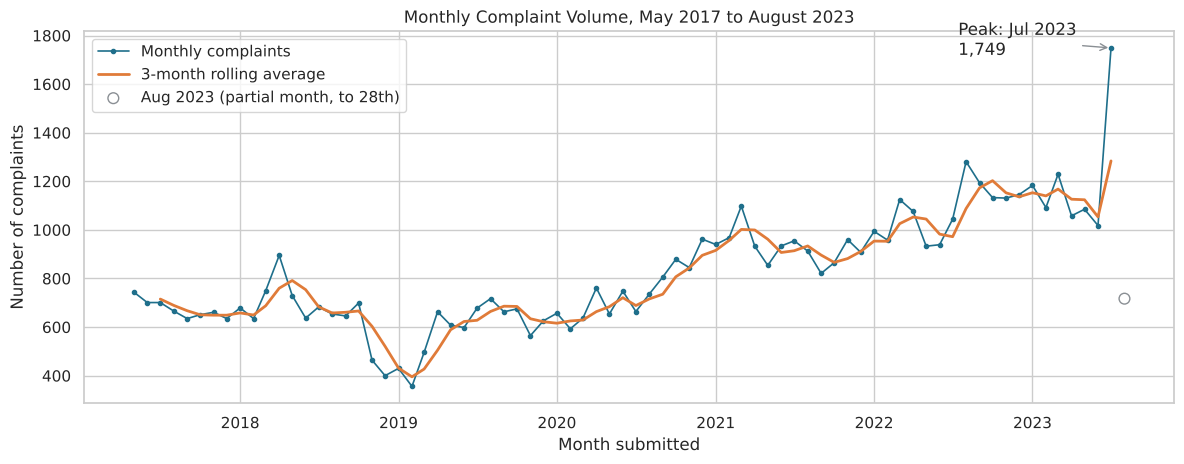

Months covered: 76 (first May 2017, last Aug 2023) | no missing months: True
Lowest months: {'Feb 2019': 356, 'Dec 2018': 400, 'Jan 2019': 430, 'Nov 2018': 464}
Exploratory trend (full months): Spearman rho between time and monthly volume = 0.80, p < 0.001
Busiest month: July 2023 with 1,749 complaints, 1.5 times the average of the previous 12 months (1,133)


In [13]:
monthly = df.groupby("year_month").size(); monthly.index = monthly.index.to_timestamp()
full_months = monthly.iloc[:-1]                                    # August 2023 ends on the 28th (partial)
roll3 = full_months.rolling(3).mean()

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(full_months.index, full_months.values, color=BLUE, marker="o", ms=3, lw=1.2, label="Monthly complaints")
ax.plot(roll3.index, roll3.values, color=ORANGE, lw=2, label="3-month rolling average")
ax.scatter(monthly.index[-1], monthly.iloc[-1], facecolors="none", edgecolors=GREY, s=60, label="Aug 2023 (partial month, to 28th)")
peak_month = full_months.idxmax()
ax.annotate(f"Peak: {peak_month:%b %Y}\n{int(full_months.max()):,}", (peak_month, full_months.max()), xytext=(-110, -5), textcoords="offset points", arrowprops=dict(arrowstyle="->", color=GREY))
ax.set_title("Monthly Complaint Volume, May 2017 to August 2023"); ax.set_xlabel("Month submitted"); ax.set_ylabel("Number of complaints"); ax.legend()
save_fig("02_monthly_volume.png")

rho_trend, p_trend = stats.spearmanr(np.arange(len(full_months)), full_months.values)
prev12 = full_months.iloc[-13:-1]
spike_ratio = full_months.iloc[-1] / prev12.mean()
print(f"Months covered: {len(monthly)} (first {monthly.index[0]:%b %Y}, last {monthly.index[-1]:%b %Y}) | no missing months: {len(pd.period_range(df['year_month'].min(), df['year_month'].max(), freq='M')) == len(monthly)}")
print("Lowest months:", {f"{k:%b %Y}": int(v) for k, v in full_months.nsmallest(4).items()})
print(f"Exploratory trend (full months): Spearman rho between time and monthly volume = {rho_trend:.2f}, p {fmt_p(p_trend)}")
print(f"Busiest month: {peak_month:%B %Y} with {int(full_months.max()):,} complaints, {spike_ratio:.1f} times the average of the previous 12 months ({prev12.mean():,.0f})")
RESULTS.update({"trend_rho": float(rho_trend), "peak_month": f"{peak_month:%B %Y}", "peak_month_n": int(full_months.max()), "spike_ratio": float(spike_ratio),
                "prev12_mean": float(prev12.mean()), "n_months": int(len(monthly))})
monthly.rename("complaints").to_csv(f"{TAB}/monthly_volume.csv")

**Shows:** a rising overall trend with month-to-month noise, and one outlier month (the peak above), the busiest on record and above anything in the preceding years. The lowest months fall around the turn of 2018–2019. The sequence has no missing months.
**Cannot show:** the cause of the spike. The next chart inspects it. The trend statistic is exploratory only: consecutive months are not independent, so its p-value should not be over-read.

## 5.3 The busiest month, day by day

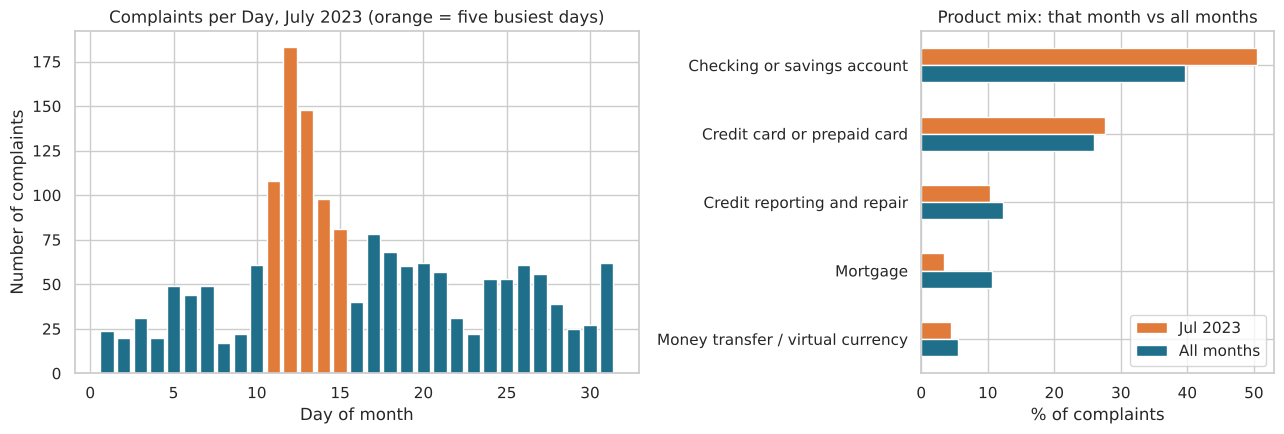

The five busiest days account for 35% of that month's complaints; busiest days: {12: 183, 13: 148, 11: 108, 14: 98, 15: 81}
'Managing an account' share: 24.3% that month vs 24.2% overall | previous highest month: 1,281


,Jul 2023,All months
product_short,,
Checking or savings account,50.5,39.7
Credit card or prepaid card,27.6,25.9
Credit reporting and repair,10.4,12.3
Mortgage,3.4,10.6
Money transfer / virtual currency,4.4,5.5


In [14]:
pk = df[df["year_month"] == pd.Period(peak_month, "M")]
daily = pk.groupby(pk["date_submitted"].dt.day).size()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].bar(daily.index, daily.values, color=[ORANGE if v >= daily.nlargest(5).min() else BLUE for v in daily.values])
axes[0].set_title(f"Complaints per Day, {peak_month:%B %Y} (orange = five busiest days)"); axes[0].set_xlabel("Day of month"); axes[0].set_ylabel("Number of complaints")
top5p = df["product_short"].value_counts().head(5).index
mix = pk["product_short"].value_counts(normalize=True).reindex(top5p) * 100
base = df["product_short"].value_counts(normalize=True).reindex(top5p) * 100
cmp = pd.DataFrame({f"{peak_month:%b %Y}": mix, "All months": base}).round(1)
cmp.plot.barh(ax=axes[1], color=[ORANGE, BLUE]); axes[1].invert_yaxis(); axes[1].set_xlabel("% of complaints"); axes[1].set_title("Product mix: that month vs all months"); axes[1].set_ylabel("")
save_fig("03_peak_month_daily.png")
top5_share = daily.nlargest(5).sum() / daily.sum()
ma_peak, ma_all = (pk["issue"] == "Managing an account").mean() * 100, (df["issue"] == "Managing an account").mean() * 100
prev_max = full_months.iloc[:-1].max()
print(f"The five busiest days account for {top5_share:.0%} of that month's complaints; busiest days: {daily.nlargest(5).to_dict()}")
print(f"'Managing an account' share: {ma_peak:.1f}% that month vs {ma_all:.1f}% overall | previous highest month: {int(prev_max):,}")
RESULTS.update({"peak_checking_share": float(mix.iloc[0]), "all_checking_share": float(base.iloc[0]), "prev_max_month": int(prev_max), "peak_top5_days": {int(k): int(v) for k, v in daily.nlargest(5).items()}, "peak_top5_share": float(top5_share)})
display(cmp)

**Shows:** the spike is concentrated in a handful of consecutive days in the middle of the month rather than spread evenly. The product mix leans toward checking and savings accounts (about half of that month's complaints against about 40% overall) but the same large products dominate, and the issue mix is almost unchanged ("Managing an account" is about a quarter in both), so it is not driven by one unusual product or issue.
**Cannot show:** what happened on those days. Possible explanations (a news event, an outage, a campaign, a batch of related complaints) cannot be tested with this dataset and are **not** asserted.

## 5.4 Complaints by financial product

,complaints,share_%,cumulative_%
product_short,,,
Checking or savings account,24814,39.7,39.7
Credit card or prepaid card,16197,25.9,65.6
Credit reporting and repair,7710,12.3,77.9
Mortgage,6601,10.6,88.5
Money transfer / virtual currency,3453,5.5,94.0
Debt collection,2736,4.4,98.4
Vehicle loan or lease,633,1.0,99.4
"Payday, title or personal loan",333,0.5,99.9
Student loan,39,0.1,100.0


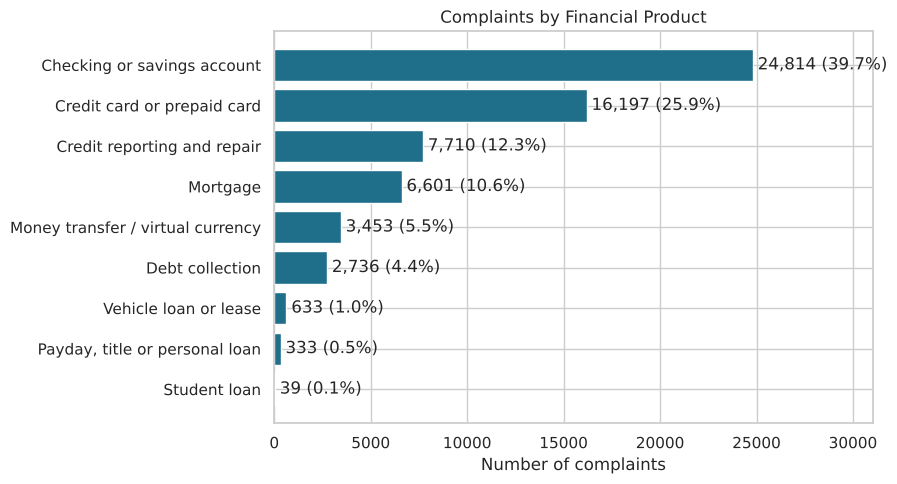

In [15]:
prod = df["product_short"].value_counts().to_frame("complaints"); prod["share_%"] = (prod["complaints"] / len(df) * 100).round(1)
prod["cumulative_%"] = prod["share_%"].cumsum().round(1)
display(prod); prod.to_csv(f"{TAB}/product_volume.csv")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(prod.index, prod["complaints"], color=BLUE); ax.invert_yaxis()
for i, (v, s) in enumerate(zip(prod["complaints"], prod["share_%"])): ax.text(v + 250, i, f"{v:,} ({s}%)", va="center")
ax.set_xlim(0, prod["complaints"].max() * 1.25); ax.set_title("Complaints by Financial Product"); ax.set_xlabel("Number of complaints"); ax.set_ylabel("")
save_fig("04_complaints_by_product.png")
RESULTS.update({"top_product": prod.index[0], "top_product_n": int(prod.iloc[0, 0]), "top_product_share": float(prod.iloc[0, 1]),
                "top2_share": float(prod["share_%"].iloc[:2].sum()), "top4_share": float(prod["share_%"].iloc[:4].sum()),
                "product_counts": {k: int(v) for k, v in prod["complaints"].items()}})

**Shows:** a concentrated pattern. Two products account for roughly two-thirds of complaints and four for about nine in ten; student loans have very few.
**Cannot show:** whether a product is *worse* than another. Banks have far more checking accounts and cards than other products, so volume largely reflects how widely a product is used (no denominator is available).

## 5.5 Most frequently reported issues, and sub-products and sub-issues

,complaints,share_%
issue,,
Managing an account,15109,24.2
Incorrect information on your report,4931,7.9
Problem with a purchase shown on your statement,4415,7.1
Closing an account,2953,4.7
Trouble during payment process,2827,4.5
Opening an account,2725,4.4
Problem with a lender or other company charging your account,2493,4.0
Fraud or scam,1987,3.2
Struggling to pay mortgage,1904,3.0


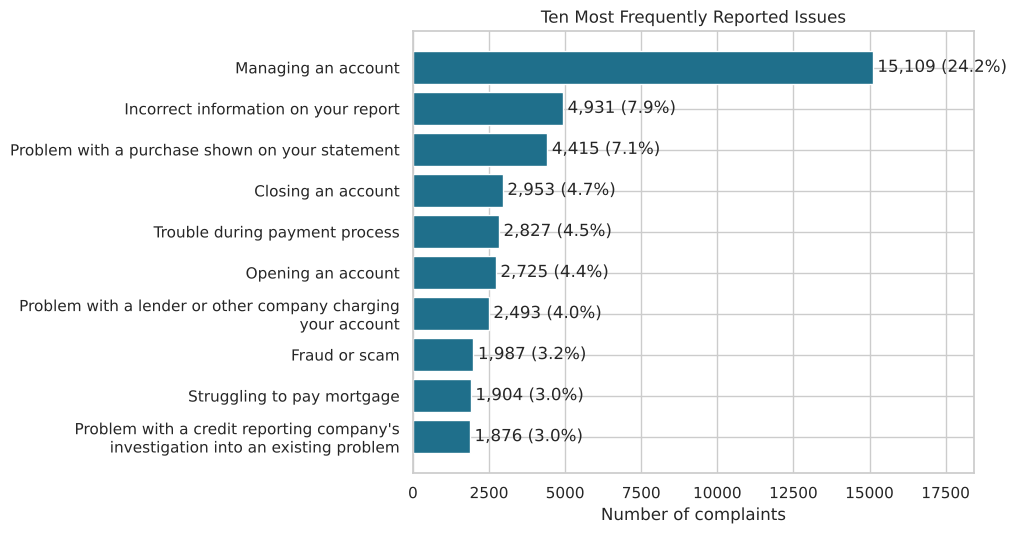

,complaints,share_%
sub_product,,
Checking account,20768,33.2
General-purpose credit card or charge card,13404,21.4
Credit reporting,7340,11.7
Conventional home mortgage,3767,6.0
Other banking product or service,2568,4.1
Government benefit card,2429,3.9
Domestic (US) money transfer,1773,2.8
Credit card debt,1697,2.7


,complaints
sub_issue,
Deposits and withdrawals,5596
Problem using a debit or ATM card,3356
Credit card company isn't resolving a dispute about a purchase on your statement,2770
Information belongs to someone else,2401
Company closed your account,2312
Transaction was not authorized,2026
Account opened as a result of fraud,1542
Card was charged for something you did not purchase with the card,1542


In [16]:
issue = df["issue"].value_counts().head(10).to_frame("complaints"); issue["share_%"] = (issue["complaints"] / len(df) * 100).round(1)
display(issue)
issue_all = df["issue"].value_counts().to_frame("complaints"); issue_all["share_%"] = (issue_all["complaints"] / len(df) * 100).round(2); issue_all.to_csv(f"{TAB}/issue_volume.csv")
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh([wrap(i, 48) for i in issue.index], issue["complaints"], color=BLUE); ax.invert_yaxis()
for i, (v, s) in enumerate(zip(issue["complaints"], issue["share_%"])): ax.text(v + 150, i, f"{v:,} ({s}%)", va="center")
ax.set_xlim(0, issue["complaints"].max() * 1.22); ax.set_title("Ten Most Frequently Reported Issues"); ax.set_xlabel("Number of complaints"); ax.set_ylabel("")
save_fig("05_top_issues.png")
sp = df["sub_product"].value_counts().head(8).to_frame("complaints"); sp["share_%"] = (sp["complaints"] / len(df) * 100).round(1)
si = df.loc[df["sub_issue"] != "Not recorded / not applicable", "sub_issue"].value_counts().head(8).to_frame("complaints")
display(sp); display(si)
df["sub_product"].value_counts().to_csv(f"{TAB}/sub_product_volume.csv"); df["sub_issue"].value_counts().to_csv(f"{TAB}/sub_issue_volume.csv")
RESULTS.update({"top_issue": issue.index[0], "top_issue_n": int(issue.iloc[0, 0]), "top_issue_share": float(issue.iloc[0, 1]), "top3_issues": issue.index[:3].tolist(),
                "top3_issue_share": float(issue["share_%"].iloc[:3].sum()), "top_sub_product": sp.index[0], "top_sub_product_share": float(sp.iloc[0, 1])})

**Shows:** "Managing an account" is by far the most reported issue (about a quarter of all complaints), followed by credit-report accuracy and disputed purchases. Within products, checking accounts and general-purpose credit cards dominate the sub-product counts.
**Cannot show:** the detail of what each complaint was about (no narratives). An issue label is the consumer's selection from a fixed list, not a verified finding.

## 5.6 How issues differ across products
The table and heatmap show, for each of the five biggest products, the share of *its own* complaints taken by its top three issues. Issue lists depend on the product, so blank cells mean the issue is not used for that product.

,product,rank,issue,complaints,share_of_product_%
0,Checking or savings account,1,Managing an account,15109,60.9
1,Checking or savings account,2,Closing an account,2953,11.9
2,Checking or savings account,3,Opening an account,2725,11.0
3,Credit card or prepaid card,1,Problem with a purchase shown on your statement,4415,27.3
4,Credit card or prepaid card,2,Getting a credit card,1867,11.5
5,Credit card or prepaid card,3,"Other features, terms, or problems",1633,10.1
6,Credit reporting and repair,1,Incorrect information on your report,4145,53.8
7,Credit reporting and repair,2,Problem with a credit reporting company's investigation into an existing pro...,1641,21.3
8,Credit reporting and repair,3,Improper use of your report,1517,19.7
9,Mortgage,1,Trouble during payment process,2827,42.8


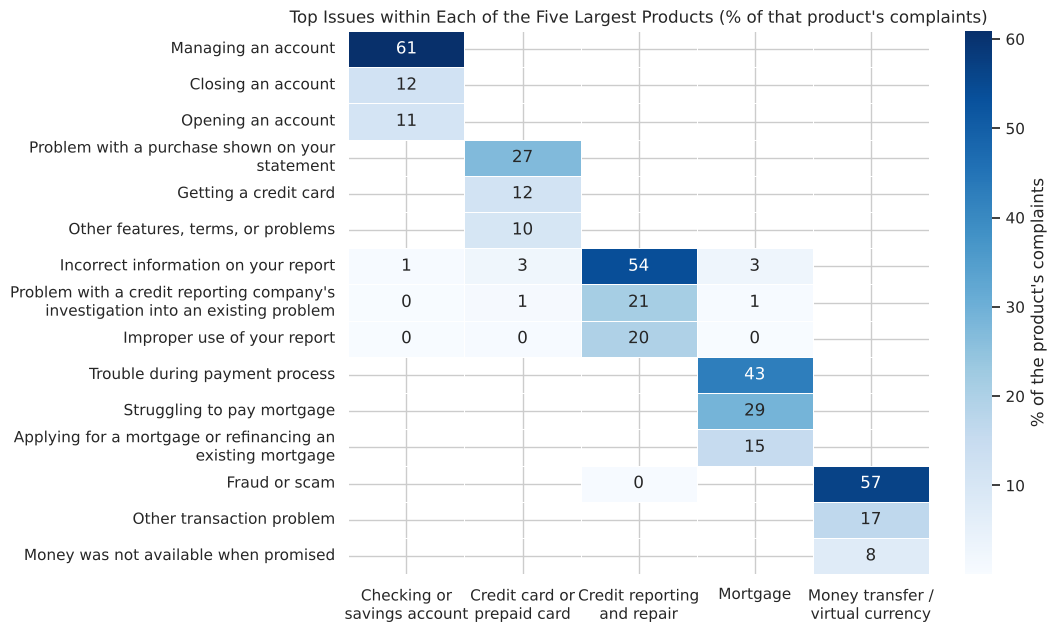

In [17]:
top_products = df["product_short"].value_counts().head(5).index.tolist()
top_issues = []
rows = []
for p in top_products:
    sub = df[df["product_short"] == p]
    vc = sub["issue"].value_counts().head(3)
    for rank, (iss, n) in enumerate(vc.items(), 1):
        rows.append({"product": p, "rank": rank, "issue": iss, "complaints": int(n), "share_of_product_%": round(n / len(sub) * 100, 1)})
        if iss not in top_issues: top_issues.append(iss)
pi_table = pd.DataFrame(rows); display(pi_table); pi_table.to_csv(f"{TAB}/product_top_issues.csv", index=False)

heat = pd.DataFrame({p: df[df["product_short"] == p]["issue"].value_counts(normalize=True).reindex(top_issues) * 100 for p in top_products})
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Blues", mask=heat.isna(), cbar_kws={"label": "% of the product's complaints"}, linewidths=.5, ax=ax)
ax.set_yticklabels([wrap(t.get_text(), 42) for t in ax.get_yticklabels()], rotation=0); ax.set_xticklabels([wrap(t.get_text(), 16) for t in ax.get_xticklabels()], rotation=0)
ax.set_title("Top Issues within Each of the Five Largest Products (% of that product's complaints)"); ax.set_xlabel(""); ax.set_ylabel("")
save_fig("06_product_issue_heatmap.png")
RESULTS["product_issue_table"] = pi_table.to_dict("records")

**Shows:** issue profiles are product-specific. Checking-account complaints are dominated by account management (about 61% of that product's complaints), card complaints are spread across purchase disputes (about 27%), applying for a card and other features, credit-reporting complaints concentrate on incorrect information (about 54%) and investigations, mortgage complaints on trouble during payment (about 43%), and money-transfer complaints on fraud or scams (about 57%).
**Cannot show:** causes, or whether an issue is rising or falling (this view is aggregated across all years).

## 5.7 Recorded company responses

,complaints,share_%
company_response,,
Closed with explanation,41044,65.65
Closed with monetary relief,14697,23.51
Closed with non-monetary relief,5273,8.43
In progress,1494,2.39
Closed,8,0.01


,complaints,share_%
public_response,,
Company has responded to the consumer and the CFPB and chooses not to provide a public response,60311,96.47
Not provided,2175,3.48
Company believes the complaint provided an opportunity to answer consumer's questions,12,0.02
Company believes the complaint is the result of a misunderstanding,7,0.01
Company believes it acted appropriately as authorized by contract or law,6,0.01
Company believes complaint caused principally by actions of third party outside the control or direction of the company,3,0.00
Company disputes the facts presented in the complaint,2,0.00


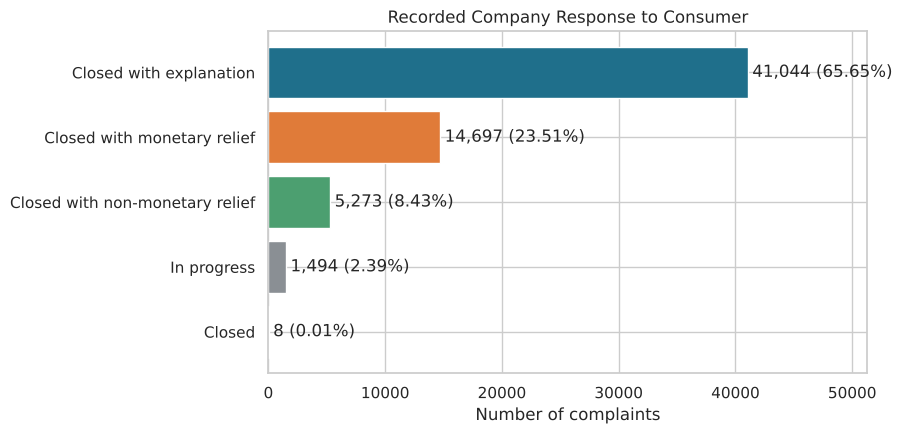

In [18]:
resp = df["company_response"].value_counts().to_frame("complaints"); resp["share_%"] = (resp["complaints"] / len(df) * 100).round(2)
display(resp); resp.to_csv(f"{TAB}/company_response_distribution.csv")
pub = df["public_response"].value_counts().to_frame("complaints"); pub["share_%"] = (pub["complaints"] / len(df) * 100).round(2)
display(pub); pub.to_csv(f"{TAB}/public_response_distribution.csv")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(resp.index, resp["complaints"], color=[BLUE, ORANGE, GREEN, GREY, GREY]); ax.invert_yaxis()
for i, (v, s) in enumerate(zip(resp["complaints"], resp["share_%"])): ax.text(v + 400, i, f"{v:,} ({s}%)", va="center")
ax.set_xlim(0, resp["complaints"].max() * 1.25); ax.set_title("Recorded Company Response to Consumer"); ax.set_xlabel("Number of complaints"); ax.set_ylabel("")
save_fig("07_company_response.png")
closed = df[~df["company_response"].isin(["In progress", "Closed"])]
RESULTS.update({"resp_dist": {k: int(v) for k, v in resp["complaints"].items()}, "resp_share": {k: float(v) for k, v in resp["share_%"].items()},
                "relief_share_closed": float(closed["company_response"].isin(["Closed with monetary relief", "Closed with non-monetary relief"]).mean() * 100),
                "n_in_progress": int(df["in_progress_flag"].sum()), "pub_nochoice_share": float(pub.loc[pub.index.str.startswith("Company has responded"), "share_%"].sum())})

**Shows:** most complaints are closed *with explanation*; about one in three closed complaints carries some form of relief (monetary or non-monetary). A small number are still in progress. Almost every public response is the standard "chooses not to provide a public response" option, so the public-response field carries very little information.
**Cannot show:** whether the consumer was satisfied, or whether relief was appropriate. A recorded category is the company's classification, **not proof of resolution**.

## 5.8 Recorded timely response
Only complaints with a valid Yes or No count in the denominator. The blanks (all "In progress") are reported separately and are **not** treated as "No".

Valid Yes/No records: 61,022 | excluded (blank, In progress): 1,494
Timely response = Yes: 58,619 (96.06%) | No: 2,403 (3.94%)


,valid_records,no_count,no_rate_%,in_progress_excluded
year,,,,
2017,5394,9,0.17,0
2018,7872,12,0.15,0
2019,7075,7,0.10,0
2020,8942,62,0.69,0
2021,11149,1224,10.98,0
2022,12953,567,4.38,0
2023,7637,522,6.84,1494


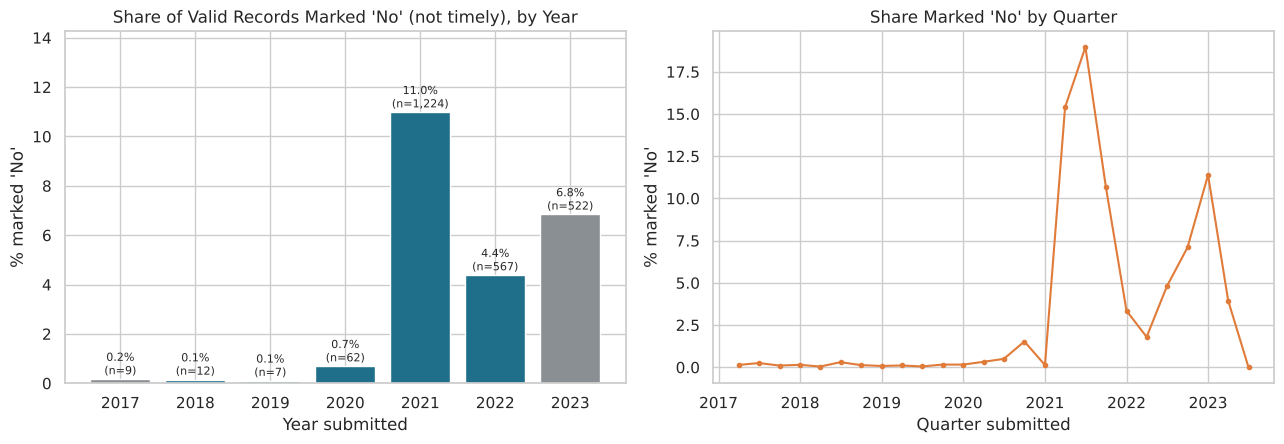

Highest quarterly 'No' rates (%): {'2021Q3': 19.0, '2021Q2': 15.4, '2023Q1': 11.4, '2021Q4': 10.6, '2022Q4': 7.1}


In [19]:
valid = df[df["timely_valid"]]
n_valid, n_excl = len(valid), int((~df["timely_valid"]).sum())
timely_pct = (valid["timely_response"] == "Yes").mean()
print(f"Valid Yes/No records: {n_valid:,} | excluded (blank, In progress): {n_excl:,}")
print(f"Timely response = Yes: {int((valid['timely_response'] == 'Yes').sum()):,} ({pct(timely_pct, 2)}) | No: {int((valid['timely_response'] == 'No').sum()):,} ({pct(1 - timely_pct, 2)})")

by_year = valid.groupby("year")["timely_response"].agg(valid_records="count", no_count=lambda s: (s == "No").sum())
by_year["no_rate_%"] = (by_year["no_count"] / by_year["valid_records"] * 100).round(2)
by_year["in_progress_excluded"] = df[~df["timely_valid"]].groupby("year").size().reindex(by_year.index).fillna(0).astype(int)
display(by_year); by_year.to_csv(f"{TAB}/timely_response_by_year.csv")
by_q = valid.groupby("year_quarter")["timely_response"].apply(lambda s: (s == "No").mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].bar(by_year.index.astype(str), by_year["no_rate_%"], color=[GREY if y in PARTIAL_YEARS else BLUE for y in by_year.index])
for x, (v, n) in enumerate(zip(by_year["no_rate_%"], by_year["no_count"])): axes[0].text(x, v + 0.2, f"{v:.1f}%\n(n={n:,})", ha="center", fontsize=8)
axes[0].set_ylim(0, by_year["no_rate_%"].max() * 1.3); axes[0].set_title("Share of Valid Records Marked 'No' (not timely), by Year"); axes[0].set_xlabel("Year submitted"); axes[0].set_ylabel("% marked 'No'")
axes[1].plot(by_q.index.to_timestamp(), by_q.values, color=ORANGE, marker="o", ms=3)
axes[1].set_title("Share Marked 'No' by Quarter"); axes[1].set_xlabel("Quarter submitted"); axes[1].set_ylabel("% marked 'No'")
save_fig("08_timely_response.png")
worst_q = by_q.idxmax()
print("Highest quarterly 'No' rates (%):", {str(k): round(float(v), 1) for k, v in by_q.sort_values(ascending=False).head(5).items()})
RESULTS.update({"n_valid_timely": int(n_valid), "n_excluded_timely": n_excl, "timely_yes_pct": float(timely_pct * 100), "timely_no_n": int((valid["timely_response"] == "No").sum()),
                "no_rate_by_year": {int(k): float(v) for k, v in by_year["no_rate_%"].items()}, "no_n_by_year": {int(k): int(v) for k, v in by_year["no_count"].items()},
                "worst_quarter": str(worst_q), "worst_quarter_rate": float(by_q.max()), "no_2018_2019_rate": float(valid[valid["year"].isin([2018, 2019])]["timely_response"].eq("No").mean() * 100)})

**Shows:** about 96% of valid records are marked timely, so the overall figure looks strong, but it hides a clear pattern over time: "No" was extremely rare until 2020, then jumped in 2021 and stayed above its earlier level in 2022–2023. The quarterly view shows that the rise arrives in bursts rather than gradually: it peaks in the second to fourth quarters of 2021 and again in the first quarter of 2023, with quieter quarters between. (Q3 2023 is a partial quarter with many complaints still in progress.)
**Cannot show:** what "timely" was measured against, why more complaints were marked "No", or whether this reflects company performance, case volumes, a rule change or how the indicator was recorded. 2023 excludes all in-progress complaints, so it is not a completed picture.

## 5.9 Has the response mix changed over time?

company_response,Closed,Closed with explanation,Closed with monetary relief,Closed with non-monetary relief,In progress
year,,,,,
2017,0.00,69.19,22.51,8.31,0.00
2018,0.03,67.02,25.30,7.65,0.00
2019,0.00,67.31,24.51,8.18,0.00
2020,0.00,66.46,25.33,8.21,0.00
2021,0.00,68.84,25.23,5.93,0.00
2022,0.00,65.50,23.52,10.99,0.00
2023,0.07,56.64,17.88,9.05,16.36


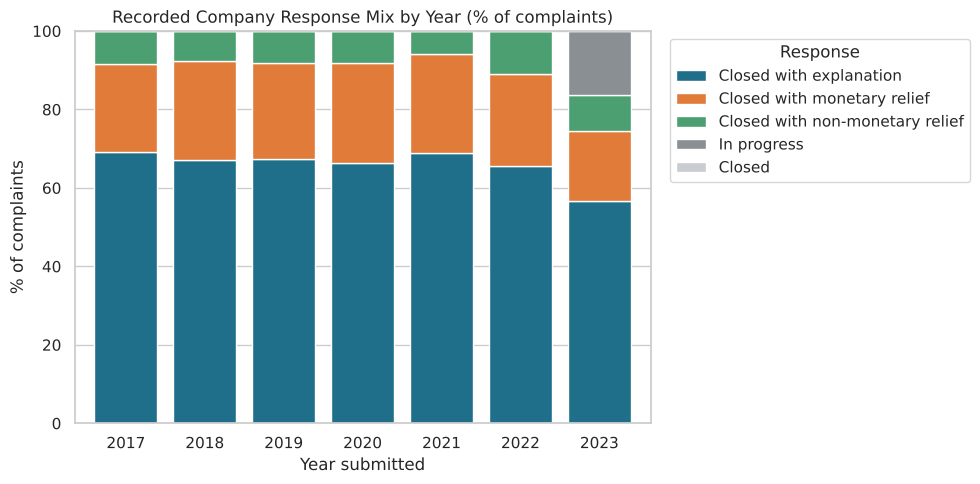

Share of closed complaints with some relief, by year (%):
year
2017    30.8
2018    33.0
2019    32.7
2020    33.5
2021    31.2
2022    34.5
2023    32.2


In [20]:
mix_year = pd.crosstab(df["year"], df["company_response"], normalize="index") * 100
display(mix_year.round(2)); mix_year.round(2).to_csv(f"{TAB}/response_mix_by_year.csv")
order = ["Closed with explanation", "Closed with monetary relief", "Closed with non-monetary relief", "In progress", "Closed"]
fig, ax = plt.subplots(figsize=(10, 5))
mix_year[order].plot.bar(stacked=True, ax=ax, color=[BLUE, ORANGE, GREEN, GREY, "#c9ccd0"], width=0.8)
ax.set_title("Recorded Company Response Mix by Year (% of complaints)"); ax.set_xlabel("Year submitted"); ax.set_ylabel("% of complaints"); ax.legend(title="Response", bbox_to_anchor=(1.02, 1), loc="upper left"); ax.tick_params(axis="x", rotation=0)
save_fig("09_response_mix_by_year.png")
closed_year = df[~df["company_response"].isin(["In progress", "Closed"])].groupby("year")["company_response"].apply(lambda s: s.isin(["Closed with monetary relief", "Closed with non-monetary relief"]).mean() * 100)
print("Share of closed complaints with some relief, by year (%):"); print(closed_year.round(1).to_string())
RESULTS["relief_by_year"] = {int(k): float(v) for k, v in closed_year.items()}

**Shows:** the overall share of *closed* complaints carrying some relief is stable at roughly 31–35% in every year, but the split between monetary and non-monetary relief moves (non-monetary relief was about 6% of complaints in 2021 and about 11% in 2022). The lower 2023 share of "closed with explanation" is mostly because 16% of 2023 complaints are still in progress.
**Cannot show:** why the mix changed. Differences may reflect changes in case mix (products and issues), company policy, or how categories were recorded.

## 5.10 CFPB forwarding interval
This is the time between the CFPB receiving a complaint and sending it to the company, **not** how long the company took to respond.

,complaints,share_%
interval_band,,
Same day,49634,79.39
1 day,5575,8.92
2–3 days,2856,4.57
4–7 days,2008,3.21
8–30 days,2008,3.21
Over 30 days,435,0.70


Mean 1.22 days | median 0 | 90th percentile 2 | 99th percentile 25 | maximum 275


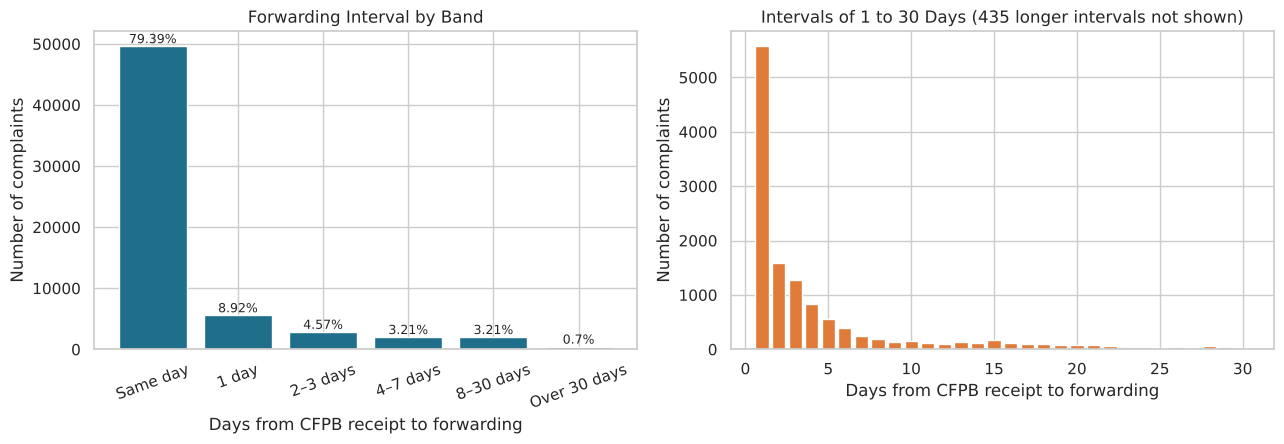

In [21]:
iv = df["interval_days"]
band = df["interval_band"].value_counts().reindex(bands).to_frame("complaints"); band["share_%"] = (band["complaints"] / len(df) * 100).round(2)
display(band); band.to_csv(f"{TAB}/forwarding_interval_bands.csv")
print(f"Mean {iv.mean():.2f} days | median {iv.median():.0f} | 90th percentile {iv.quantile(.9):.0f} | 99th percentile {iv.quantile(.99):.0f} | maximum {int(iv.max())}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].bar(band.index, band["complaints"], color=BLUE)
for x, (v, s) in enumerate(zip(band["complaints"], band["share_%"])): axes[0].text(x, v + 500, f"{s}%", ha="center", fontsize=9)
axes[0].set_title("Forwarding Interval by Band"); axes[0].set_xlabel("Days from CFPB receipt to forwarding"); axes[0].set_ylabel("Number of complaints"); axes[0].tick_params(axis="x", rotation=20)
day_counts = iv[(iv >= 1) & (iv <= 30)].value_counts().sort_index()
axes[1].bar(day_counts.index, day_counts.values, color=ORANGE)
axes[1].set_title(f"Intervals of 1 to 30 Days ({int((iv > 30).sum())} longer intervals not shown)"); axes[1].set_xlabel("Days from CFPB receipt to forwarding"); axes[1].set_ylabel("Number of complaints")
save_fig("10_forwarding_interval.png")
RESULTS.update({"iv_mean": float(iv.mean()), "iv_median": float(iv.median()), "iv_p90": float(iv.quantile(.9)), "iv_p99": float(iv.quantile(.99)), "iv_max": int(iv.max()),
                "same_day_n": int((iv == 0).sum()), "same_day_pct": float((iv == 0).mean() * 100), "gt7_n": int((iv > 7).sum()), "gt7_pct": float((iv > 7).mean() * 100),
                "gt30_n": int((iv > 30).sum()), "gt30_pct": float((iv > 30).mean() * 100)})

**Shows:** for roughly four in five complaints the CFPB forwarded the complaint on the day it was received, so the median is zero. A small tail of intervals runs from a week to many months, which pulls the mean above the median.
**Cannot show:** why any given complaint took longer. Likely reasons (for example a referral from another agency, or checks by the CFPB before forwarding) are not recorded.

## 5.11 Unusually long forwarding intervals
"Unusually long" is defined here as **more than 30 days** (the standard IQR rule is unusable because the upper quartile is 0). These records are flagged, not removed.

In [22]:
long = df[df["long_interval_flag"]]
by_channel = df.groupby("channel_group").agg(complaints=("complaint_id", "count"), mean_days=("interval_days", "mean"), median_days=("interval_days", "median"),
                                               same_day_pct=("interval_days", lambda s: (s == 0).mean() * 100), over_30_n=("long_interval_flag", "sum"),
                                               over_30_pct=("long_interval_flag", lambda s: s.mean() * 100)).round(2).sort_values("complaints", ascending=False)
display(by_channel); by_channel.to_csv(f"{TAB}/interval_by_channel.csv")
print("\nLong-interval (>30 days) complaints by year:", long.groupby("year").size().to_dict())
print(f"Referral share of all complaints: {(df['channel_group'] == 'Referral').mean():.1%} | referral share of >30-day complaints: {(long['channel_group'] == 'Referral').mean():.1%}")
display(long.nlargest(10, "interval_days")[["complaint_id", "year", "product_short", "channel_group", "interval_days", "company_response"]].reset_index(drop=True))
ref_by_year = df.groupby("year")["channel_group"].apply(lambda s: (s == "Referral").mean() * 100).round(1)
print("\nReferral share of complaints by year (%):", ref_by_year.to_dict())
RESULTS.update({"referral_share_all": float((df['channel_group'] == 'Referral').mean() * 100), "referral_share_long": float((long['channel_group'] == 'Referral').mean() * 100),
                "web_same_day": float(by_channel.loc["Web", "same_day_pct"]), "referral_same_day": float(by_channel.loc["Referral", "same_day_pct"]),
                "web_mean": float(by_channel.loc["Web", "mean_days"]), "referral_mean": float(by_channel.loc["Referral", "mean_days"]),
                "referral_median": float(by_channel.loc["Referral", "median_days"]), "ref_by_year": {int(k): float(v) for k, v in ref_by_year.items()},
                "long_by_year": {int(k): int(v) for k, v in long.groupby("year").size().items()}})

,complaints,mean_days,median_days,same_day_pct,over_30_n,over_30_pct
channel_group,,,,,,
Web,45423,0.68,0.0,92.22,162,0.36
Referral,10856,3.28,1.0,24.59,207,1.91
Phone,4684,1.79,0.0,79.95,57,1.22
Postal mail,1318,1.27,0.0,85.51,9,0.68
Fax or email,235,0.49,0.0,86.38,0,0.00



Long-interval (>30 days) complaints by year: {2017: 45, 2018: 82, 2019: 102, 2020: 12, 2021: 34, 2022: 46, 2023: 114}
Referral share of all complaints: 17.4% | referral share of >30-day complaints: 47.6%


,complaint_id,year,product_short,channel_group,interval_days,company_response
0,4481803,2021,Debt collection,Web,275,Closed with explanation
1,2879520,2017,Credit card or prepaid card,Postal mail,181,Closed with non-monetary relief
2,3016782,2018,Mortgage,Postal mail,179,Closed with explanation
3,4490086,2021,Credit card or prepaid card,Web,161,Closed with explanation
4,3316804,2019,Mortgage,Referral,153,Closed with explanation
5,3016783,2018,Checking or savings account,Postal mail,130,Closed with explanation
6,5773942,2022,Debt collection,Postal mail,129,Closed with explanation
7,5045425,2021,Mortgage,Web,128,Closed with explanation
8,2627415,2017,Debt collection,Web,123,Closed with explanation
9,3384869,2019,Credit card or prepaid card,Referral,109,Closed with explanation



Referral share of complaints by year (%): {2017: 23.8, 2018: 27.1, 2019: 24.3, 2020: 19.9, 2021: 18.5, 2022: 11.7, 2023: 4.0}


**Shows:** the submission channel matters a great deal. Web, phone, postal-mail and fax complaints are mostly forwarded the same day, whereas referral complaints (complaints passed on from another agency) are rarely forwarded the same day and are over-represented among the longest intervals. The referral share has also fallen sharply over the years, which complicates any year-to-year comparison of intervals.
**Cannot show:** the cause of individual delays. Channel is a plausible explanation, but it is an association; other factors (such as product or case complexity) are not separated out here.

---
# 6. Hypothesis testing

Three questions are tested, each chosen because it directly addresses one of the project's business questions. **Method choices follow the data:**
* Forwarding intervals are extremely skewed with many zeros, so a **rank-based** test (Kruskal–Wallis) is used instead of ANOVA.
* Response category and timeliness are categorical, so the **chi-square test of independence** is used.
* With around 60,000 records almost any difference becomes "statistically significant". Every test is therefore paired with an **effect size**, and results are judged on practical size as well as p-values. Significance is judged at 0.05.
* The three product groups with the fewest complaints (vehicle loans, payday/title/personal loans, student loans) are **combined into one group** so that every test group is large enough.

Common limitation: complaints from the same consumer cannot be identified (there is no consumer ID), so the independence assumption cannot be checked.

## 6.1 H1 – Do forwarding intervals differ across product groups?
* **H0:** the distribution of forwarding intervals is the same for every product group.
* **H1:** at least one product group has a different distribution.
* **Test:** Kruskal–Wallis. **Effect size:** epsilon-squared, ε² = H ÷ (n − 1) (rule of thumb: below 0.01 negligible, 0.01–0.06 small, 0.06–0.14 medium, above 0.14 large).

In [23]:
def label_eps(e): return "negligible" if e < 0.01 else "small" if e < 0.06 else "medium" if e < 0.14 else "large"
def label_v(v, k):                       # Cramer's V thresholds (Cohen's w = 0.1/0.3/0.5, divided by sqrt of min(rows, cols) - 1)
    s, m, l = [t / np.sqrt(k) for t in (0.1, 0.3, 0.5)]
    return "negligible" if v < s else "small" if v < m else "medium" if v < l else "large"

grp = df.groupby("product_group").agg(complaints=("interval_days", "count"), mean_days=("interval_days", "mean"), median_days=("interval_days", "median"),
        same_day_pct=("interval_days", lambda s: (s == 0).mean() * 100), over_7_pct=("interval_days", lambda s: (s > 7).mean() * 100),
        over_30_pct=("interval_days", lambda s: (s > 30).mean() * 100), referral_pct=("channel_group", lambda s: (s == "Referral").mean() * 100)).round(2)
grp = grp.sort_values("complaints", ascending=False)
display(grp); grp.to_csv(f"{TAB}/interval_by_product_group.csv")

print("Assumption check: smallest group size =", int(grp["complaints"].min()), "| share of intervals equal to 0 =", f"{(df['interval_days'] == 0).mean():.0%}", "| skewness =", round(df['interval_days'].skew(), 1), "-> rank-based test is appropriate")
samples = [g["interval_days"].values for _, g in df.groupby("product_group")]
H, p1 = stats.kruskal(*samples); eps2 = H / (len(df) - 1)
print(f"\nKruskal-Wallis H = {H:.1f} (df = {len(samples) - 1}), p {fmt_p(p1)}, epsilon-squared = {eps2:.3f} ({label_eps(eps2)})")

# robustness: the Web channel only (the biggest channel, and mostly same-day) removes the channel-mix explanation
web = df[df["channel_group"] == "Web"]
H_w, p_w = stats.kruskal(*[g["interval_days"].values for _, g in web.groupby("product_group")]); eps_w = H_w / (len(web) - 1)
print(f"Robustness, Web channel only (n = {len(web):,}): H = {H_w:.1f}, p {fmt_p(p_w)}, epsilon-squared = {eps_w:.3f} ({label_eps(eps_w)})")
print("Decision:", "Reject H0: intervals differ across product groups." if p1 < 0.05 else "Do not reject H0.")
RESULTS["H1"] = {"H": float(H), "df": len(samples) - 1, "p": float(p1), "eps2": float(eps2), "label": label_eps(eps2), "web_H": float(H_w), "web_p": float(p_w), "web_eps2": float(eps_w), "web_label": label_eps(eps_w), "web_n": int(len(web))}
RESULTS["interval_by_product_group"] = grp.reset_index().to_dict("records")

,complaints,mean_days,median_days,same_day_pct,over_7_pct,over_30_pct,referral_pct
product_group,,,,,,,
Checking or savings account,24814,1.23,0.0,74.15,3.33,0.63,25.16
Credit card or prepaid card,16197,1.13,0.0,82.04,3.77,0.65,14.12
Credit reporting and repair,7710,0.74,0.0,91.88,3.44,0.32,1.52
Mortgage,6601,1.86,0.0,71.87,5.48,1.41,27.16
Money transfer / virtual currency,3453,1.06,0.0,88.13,4.11,0.75,3.33
Debt collection,2736,1.64,0.0,84.36,6.58,0.77,4.42
"Vehicle, payday and student loans",1005,1.55,0.0,76.32,5.67,0.90,17.81


Assumption check: smallest group size = 1005 | share of intervals equal to 0 = 79% | skewness = 11.8 -> rank-based test is appropriate

Kruskal-Wallis H = 1508.0 (df = 6), p < 0.001, epsilon-squared = 0.024 (small)
Robustness, Web channel only (n = 45,423): H = 168.1, p < 0.001, epsilon-squared = 0.004 (negligible)
Decision: Reject H0: intervals differ across product groups.


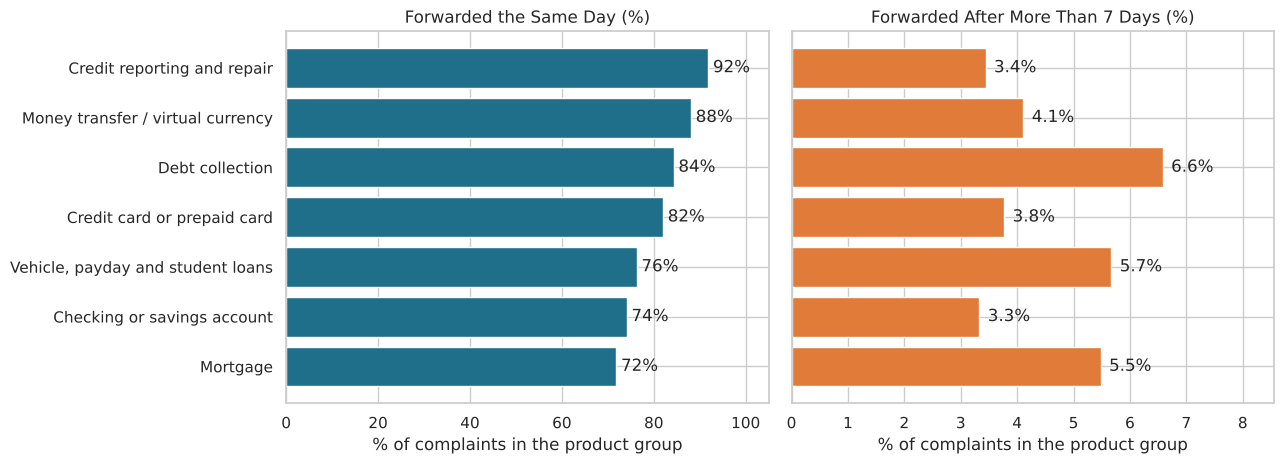

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
g1 = grp.sort_values("same_day_pct")
axes[0].barh(g1.index, g1["same_day_pct"], color=BLUE)
for i, v in enumerate(g1["same_day_pct"]): axes[0].text(v + 1, i, f"{v:.0f}%", va="center")
axes[0].set_xlim(0, 105); axes[0].set_title("Forwarded the Same Day (%)"); axes[0].set_xlabel("% of complaints in the product group")
axes[1].barh(g1.index, g1["over_7_pct"], color=ORANGE)
for i, v in enumerate(g1["over_7_pct"]): axes[1].text(v + 0.15, i, f"{v:.1f}%", va="center")
axes[1].set_xlim(0, g1["over_7_pct"].max() * 1.3); axes[1].set_title("Forwarded After More Than 7 Days (%)"); axes[1].set_xlabel("% of complaints in the product group")
save_fig("11_interval_by_product.png")

### H1 interpretation
The test finds a statistically significant difference, but the **effect is small**: product group explains very little of the variation in forwarding intervals. The pattern is more visible in the same-day share (credit reporting complaints are held least often, with about 92% forwarded the same day, while mortgage complaints are held most often, about 72%) than in averages. Importantly, the product groups also differ in how complaints reach the CFPB: the groups with the highest referral shares (mortgage and checking accounts) have the lowest same-day shares, and credit reporting has almost no referrals. Restricting the test to **Web** complaints shrinks the effect from small to **negligible**, so a good part of the product difference is likely a **channel-mix effect rather than a product effect**. Debt collection is an exception worth noting: it has few referrals but the highest share of intervals over 7 days.
**Limitation:** with many ties at zero, rank tests compare overall ordering, not medians (the medians are 0 for most groups).

## 6.2 H2 – Is the recorded company response associated with product group?
* **H0:** product group and response category are independent.
* **H1:** the response mix differs across product groups.
* **Test:** chi-square test of independence on closed complaints. "In progress" (no outcome yet) and the 8 bare "Closed" records are excluded and reported. **Effect size:** Cramér's V.

Records used: 61,014 | excluded: 1,502 (In progress 1,494 and bare 'Closed' 8)
Assumption check: smallest expected count = 85.3 (rule: all >= 5) | cells below 5 = 0


company_response,Closed with explanation,Closed with monetary relief,Closed with non-monetary relief
product_group,,,
Checking or savings account,14836,8027,1241
Credit card or prepaid card,9361,4798,1621
Credit reporting and repair,6067,273,1178
Debt collection,2367,111,209
Money transfer / virtual currency,2709,634,41
Mortgage,4928,750,876
"Vehicle, payday and student loans",776,104,107


company_response,Closed with explanation,Closed with monetary relief,Closed with non-monetary relief
product_group,,,
Checking or savings account,61.5,33.3,5.1
Credit card or prepaid card,59.3,30.4,10.3
Credit reporting and repair,80.7,3.6,15.7
Debt collection,88.1,4.1,7.8
Money transfer / virtual currency,80.1,18.7,1.2
Mortgage,75.2,11.4,13.4
"Vehicle, payday and student loans",78.6,10.5,10.8



Chi-square = 5,426 (df = 12), p < 0.001, Cramer's V = 0.211 (small)
Decision: Reject H0: the response mix differs across product groups.


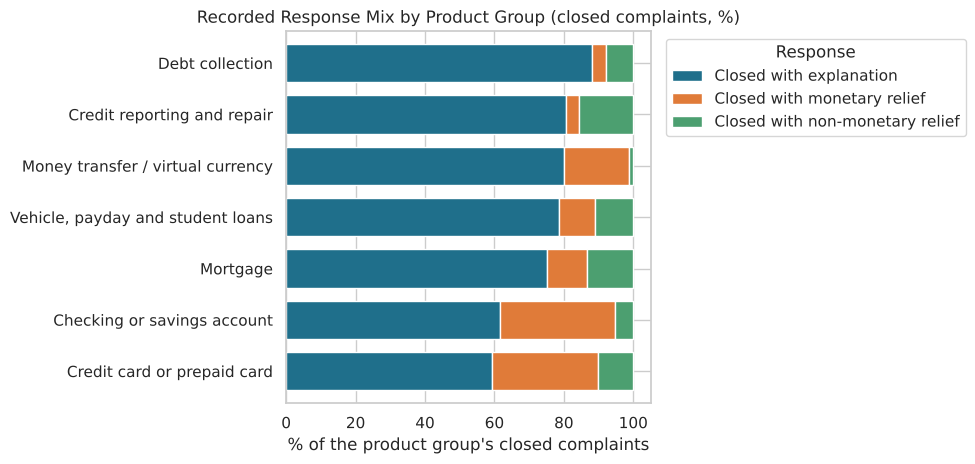

In [25]:
t2 = df[~df["company_response"].isin(["In progress", "Closed"])]
excl_h2 = len(df) - len(t2)
ct2 = pd.crosstab(t2["product_group"], t2["company_response"])
chi2_2, p2, dof2, exp2 = stats.chi2_contingency(ct2)
k2 = min(ct2.shape) - 1
V2 = np.sqrt(chi2_2 / (ct2.values.sum() * k2))
print(f"Records used: {len(t2):,} | excluded: {excl_h2:,} (In progress {int(df['in_progress_flag'].sum()):,} and bare 'Closed' {int((df['company_response'] == 'Closed').sum())})")
print(f"Assumption check: smallest expected count = {exp2.min():.1f} (rule: all >= 5) | cells below 5 = {int((exp2 < 5).sum())}")
display(ct2)
rowpct2 = (ct2.div(ct2.sum(axis=1), axis=0) * 100).round(1); display(rowpct2); rowpct2.to_csv(f"{TAB}/response_mix_by_product_group.csv")
print(f"\nChi-square = {chi2_2:,.0f} (df = {dof2}), p {fmt_p(p2)}, Cramer's V = {V2:.3f} ({label_v(V2, k2)})")
print("Decision:", "Reject H0: the response mix differs across product groups." if p2 < 0.05 else "Do not reject H0.")
RESULTS["H2"] = {"chi2": float(chi2_2), "df": int(dof2), "p": float(p2), "V": float(V2), "label": label_v(V2, k2), "n": int(len(t2)), "excluded": int(excl_h2), "min_expected": float(exp2.min())}
RESULTS["resp_by_product_group"] = rowpct2.reset_index().to_dict("records")

order2 = ["Closed with explanation", "Closed with monetary relief", "Closed with non-monetary relief"]
plot2 = rowpct2[order2].sort_values("Closed with explanation")
fig, ax = plt.subplots(figsize=(10, 4.8))
plot2.plot.barh(stacked=True, ax=ax, color=[BLUE, ORANGE, GREEN], width=0.75)
ax.set_title("Recorded Response Mix by Product Group (closed complaints, %)"); ax.set_xlabel("% of the product group's closed complaints"); ax.set_ylabel(""); ax.legend(title="Response", bbox_to_anchor=(1.02, 1), loc="upper left")
save_fig("12_response_by_product.png")

### H2 interpretation
The response mix differs significantly across product groups, with an effect at the **small-to-medium boundary** (V is just below the conventional medium threshold for this table size). Debt collection (88%) and credit reporting (81%) are most often "closed with explanation" and rarely carry monetary relief (about 4%), whereas checking accounts (33%) and credit cards (30%) most often carry **monetary relief**. Credit reporting (16%) and mortgage (13%) have the highest shares of **non-monetary** relief, and money transfer has almost none (about 1%).
**Alternative explanations:** the issues within each product differ (for example, a disputed card charge can be refunded, whereas a credit-report accuracy complaint is usually corrected), and what counts as relief varies by product. The test shows an association between product and recorded response, not that the company treats products differently, and it says nothing about whether any outcome was right.

## 6.3 H3 – Has the timely-response share changed across years?
* **H0:** the share of "No" (not timely) is the same in every year.
* **H1:** the share differs across years.
* **Test:** chi-square test of independence (year × Yes/No) on valid records only; blanks are excluded and reported. **Effect size:** Cramér's V. **Robustness:** repeated for the full years 2018–2022 only (excluding partial years).

In [26]:
v3 = df[df["timely_valid"]]
ct3 = pd.crosstab(v3["year"], v3["timely_response"])
chi2_3, p3, dof3, exp3 = stats.chi2_contingency(ct3)
k3 = min(ct3.shape) - 1
V3 = np.sqrt(chi2_3 / (ct3.values.sum() * k3))
print(f"Records used: {len(v3):,} | excluded (blank, In progress): {len(df) - len(v3):,}")
print(f"Assumption check: smallest expected count = {exp3.min():.1f} (rule: all >= 5)")
display(ct3.assign(no_rate_pct=(ct3["No"] / ct3.sum(axis=1) * 100).round(2)))
print(f"\nChi-square = {chi2_3:,.0f} (df = {dof3}), p {fmt_p(p3)}, Cramer's V = {V3:.3f} ({label_v(V3, k3)})")

ct3b = ct3.loc[2018:2022]
chi2_3b, p3b, dof3b, exp3b = stats.chi2_contingency(ct3b)
V3b = np.sqrt(chi2_3b / (ct3b.values.sum() * (min(ct3b.shape) - 1)))
print(f"Robustness, full years 2018-2022 only: chi-square = {chi2_3b:,.0f} (df = {dof3b}), p {fmt_p(p3b)}, Cramer's V = {V3b:.3f} ({label_v(V3b, min(ct3b.shape) - 1)})")
print("Decision:", "Reject H0: the timely-response share differs across years." if p3 < 0.05 else "Do not reject H0.")
RESULTS["H3"] = {"chi2": float(chi2_3), "df": int(dof3), "p": float(p3), "V": float(V3), "label": label_v(V3, k3), "n": int(len(v3)), "excluded": int(len(df) - len(v3)),
                 "robust_chi2": float(chi2_3b), "robust_p": float(p3b), "robust_V": float(V3b), "robust_label": label_v(V3b, min(ct3b.shape) - 1)}

Records used: 61,022 | excluded (blank, In progress): 1,494
Assumption check: smallest expected count = 212.4 (rule: all >= 5)


timely_response,No,Yes,no_rate_pct
year,,,
2017,9,5385,0.17
2018,12,7860,0.15
2019,7,7068,0.10
2020,62,8880,0.69
2021,1224,9925,10.98
2022,567,12386,4.38
2023,522,7115,6.84



Chi-square = 2,663 (df = 6), p < 0.001, Cramer's V = 0.209 (small)
Robustness, full years 2018-2022 only: chi-square = 2,311 (df = 4), p < 0.001, Cramer's V = 0.219 (small)
Decision: Reject H0: the timely-response share differs across years.


### H3 interpretation
The share of "No" differs significantly across years. Cramér's V is classed as **small**, but it is held down because "No" is rare overall (about 4%); the practical change, from about 0.1% to 11% in a year, is large for the indicator. The pattern is not a smooth drift: "No" was almost absent until 2020, rose steeply in 2021, and remained above its early level in 2022 and 2023. The result holds when the partial years 2017 and 2023 are dropped.
**Alternative explanations:** a change in how timeliness is recorded or defined, changes in case volumes or staffing, or one-off events could each produce this pattern. The data cannot distinguish between them. The indicator also does not say *how late* a response was.

## 6.4 Summary of the three tests

In [27]:
summary_tests = pd.DataFrame([
    {"hypothesis": "H1 Forwarding interval differs by product group", "test": "Kruskal-Wallis", "statistic": f"H = {RESULTS['H1']['H']:.1f} (df {RESULTS['H1']['df']})", "p_value": fmt_p(RESULTS['H1']['p']), "effect_size": f"epsilon-squared = {RESULTS['H1']['eps2']:.3f} ({RESULTS['H1']['label']})", "decision": "Reject H0"},
    {"hypothesis": "H2 Response category associated with product group", "test": "Chi-square independence", "statistic": f"chi-square = {RESULTS['H2']['chi2']:,.0f} (df {RESULTS['H2']['df']})", "p_value": fmt_p(RESULTS['H2']['p']), "effect_size": f"Cramer's V = {RESULTS['H2']['V']:.3f} ({RESULTS['H2']['label']})", "decision": "Reject H0"},
    {"hypothesis": "H3 Timely-response share differs across years", "test": "Chi-square independence", "statistic": f"chi-square = {RESULTS['H3']['chi2']:,.0f} (df {RESULTS['H3']['df']})", "p_value": fmt_p(RESULTS['H3']['p']), "effect_size": f"Cramer's V = {RESULTS['H3']['V']:.3f} ({RESULTS['H3']['label']})", "decision": "Reject H0"}])
with pd.option_context("display.max_colwidth", 70): display(summary_tests)
summary_tests.to_csv(f"{TAB}/hypothesis_test_results.csv", index=False)

,hypothesis,test,statistic,p_value,effect_size,decision
0,H1 Forwarding interval differs by product group,Kruskal-Wallis,H = 1508.0 (df 6),< 0.001,epsilon-squared = 0.024 (small),Reject H0
1,H2 Response category associated with product group,Chi-square independence,"chi-square = 5,426 (df 12)",< 0.001,Cramer's V = 0.211 (small),Reject H0
2,H3 Timely-response share differs across years,Chi-square independence,"chi-square = 2,663 (df 6)",< 0.001,Cramer's V = 0.209 (small),Reject H0


---
# 7. Findings
Numbers below are generated from the calculations above.

In [28]:
R = RESULTS
ja = R["janaug"]; ann = R["annual"]
show_md(f"""
1. **Complaint volume rose over the period, peaking in 2022.** Full-year volumes were {ann[2018]:,} (2018), {ann[2019]:,} (2019), {ann[2020]:,} (2020), {ann[2021]:,} (2021) and {ann[2022]:,} (2022). Comparing the same 1 January to 28 August window in every year, volume went from {ja[2018]:,} in 2018 to {ja[2023]:,} in 2023. The monthly trend is positive (Spearman ρ = {R['trend_rho']:.2f}, exploratory). *Volume reflects reporting behaviour as well as company activity, and there is no customer-base denominator.*
2. **A few products and issues dominate.** {R['top_product']} accounts for {R['top_product_share']:.1f}% of complaints; the top two products make up {R['top2_share']:.1f}% and the top four {R['top4_share']:.1f}%. "{R['top_issue']}" alone is {R['top_issue_share']:.1f}% of all complaints.
3. **The recorded timely-response rate is high overall ({R['timely_yes_pct']:.1f}% of {R['n_valid_timely']:,} valid records) but changed markedly over time** (H3 supported; the effect size is small only because "No" is rare, Cramér's V = {R['H3']['V']:.2f}). The "No" share was about {R['no_2018_2019_rate']:.1f}% in 2018–2019, reached {R['no_rate_by_year'][2021]:.1f}% in 2021 and was {R['no_rate_by_year'][2022]:.1f}% in 2022 and {R['no_rate_by_year'][2023]:.1f}% in 2023. {R['n_excluded_timely']:,} in-progress complaints are excluded from this percentage.
4. **Recorded response mix is associated with product** (H2 supported, small-to-medium effect, Cramér's V = {R['H2']['V']:.2f}). Overall, {R['resp_share']['Closed with explanation']:.1f}% of complaints were closed with explanation, {R['resp_share']['Closed with monetary relief']:.1f}% with monetary relief and {R['resp_share']['Closed with non-monetary relief']:.1f}% with non-monetary relief; {R['n_in_progress']:,} ({R['resp_share']['In progress']:.1f}%) are in progress. A recorded category is not proof of resolution.
5. **The CFPB forwards most complaints the same day.** {R['same_day_pct']:.1f}% had a zero-day interval; the median is {R['iv_median']:.0f} days and the mean {R['iv_mean']:.2f} days, with {R['gt30_n']:,} complaints ({R['gt30_pct']:.2f}%) over 30 days and a maximum of {R['iv_max']} days.
6. **Forwarding intervals differ statistically by product, but the effect is small and largely tied to submission channel** (H1: ε² = {R['H1']['eps2']:.3f}, {R['H1']['label']}; Web-only ε² = {R['H1']['web_eps2']:.3f}). Referral complaints are {R['referral_share_all']:.1f}% of all complaints but {R['referral_share_long']:.1f}% of those over 30 days, and are forwarded the same day only {R['referral_same_day']:.0f}% of the time compared with {R['web_same_day']:.0f}% for Web complaints.
7. **One month stands out.** {R['peak_month']} recorded {R['peak_month_n']:,} complaints, the highest on record (the previous highest was {R['prev_max_month']:,}) and {R['spike_ratio']:.1f} times the average of the previous 12 months ({R['prev12_mean']:,.0f}), with {R['peak_top5_share']:.0%} of that month's complaints arriving on five days. The data cannot explain why.
""")


1. **Complaint volume rose over the period, peaking in 2022.** Full-year volumes were 7,872 (2018), 7,075 (2019), 8,942 (2020), 11,149 (2021) and 12,953 (2022). Comparing the same 1 January to 28 August window in every year, volume went from 5,576 in 2018 to 9,131 in 2023. The monthly trend is positive (Spearman ρ = 0.80, exploratory). *Volume reflects reporting behaviour as well as company activity, and there is no customer-base denominator.*
2. **A few products and issues dominate.** Checking or savings account accounts for 39.7% of complaints; the top two products make up 65.6% and the top four 88.5%. "Managing an account" alone is 24.2% of all complaints.
3. **The recorded timely-response rate is high overall (96.1% of 61,022 valid records) but changed markedly over time** (H3 supported; the effect size is small only because "No" is rare, Cramér's V = 0.21). The "No" share was about 0.1% in 2018–2019, reached 11.0% in 2021 and was 4.4% in 2022 and 6.8% in 2023. 1,494 in-progress complaints are excluded from this percentage.
4. **Recorded response mix is associated with product** (H2 supported, small-to-medium effect, Cramér's V = 0.21). Overall, 65.7% of complaints were closed with explanation, 23.5% with monetary relief and 8.4% with non-monetary relief; 1,494 (2.4%) are in progress. A recorded category is not proof of resolution.
5. **The CFPB forwards most complaints the same day.** 79.4% had a zero-day interval; the median is 0 days and the mean 1.22 days, with 435 complaints (0.70%) over 30 days and a maximum of 275 days.
6. **Forwarding intervals differ statistically by product, but the effect is small and largely tied to submission channel** (H1: ε² = 0.024, small; Web-only ε² = 0.004). Referral complaints are 17.4% of all complaints but 47.6% of those over 30 days, and are forwarded the same day only 25% of the time compared with 92% for Web complaints.
7. **One month stands out.** July 2023 recorded 1,749 complaints, the highest on record (the previous highest was 1,281) and 1.5 times the average of the previous 12 months (1,133), with 35% of that month's complaints arriving on five days. The data cannot explain why.


---
# 8. Limitations and alternative explanations

* **Complaints are consumer reports, not verified facts.** Nothing here shows misconduct or a regulatory breach.
* **Recorded responses are classifications.** "Closed with explanation" or "relief" is not evidence that the consumer's problem was solved or that the outcome was appropriate.
* **No denominator.** Complaint counts are not rates. Products with more customers will have more complaints regardless of quality.
* **One company, one source, a partial period.** Findings cannot be generalised to other banks. 2017 and 2023 are partial years and August 2023 is a partial month.
* **The forwarding interval is not response time.** It describes the CFPB step only.
* **Dependence between records.** Several complaints may come from one consumer (no ID to check), which can overstate statistical certainty.
* **Large samples make small differences significant.** Effect sizes are reported for this reason, and interpretation is based on them.
* **Confounding.** Channel, product and issue mix change together over time, so year-to-year and product-to-product differences cannot be attributed to any single factor.
* **Unknown definitions.** The dataset does not define "timely" (the standard it is measured against) or the categories of relief; these were taken as recorded.
* **Missing structure.** Missing sub-issues are mostly structural, and public responses are almost uniform, so those fields were not analysed in depth.
* **No narratives.** No text analysis, sentiment or root-cause analysis is possible.

---
# 9. Recommendations

1. **Review how the "timely response" indicator is defined and recorded, especially for 2021.** The jump in "No" is the largest change in the data. Ask the data owner what "timely" means and whether anything changed in 2021 before drawing conclusions about company performance.
2. **Focus further review on the largest complaint blocks** (checking and savings accounts, credit cards, and the "Managing an account" issue), but pair counts with customer-base or transaction figures so that rates, not just volumes, can be compared.
3. **Report forwarding intervals by submission channel and treat referrals separately.** Aggregate averages hide the fact that referral complaints take longer, which is a feature of that route rather than of any product.
4. **Investigate the busiest month with additional information** (for example, event logs or related-complaint groupings) to establish whether those days were a one-off event, and monitor for similar spikes using a simple threshold such as a multiple of the trailing 12-month average.
5. **Display in-progress complaints and partial periods explicitly in all reporting** so that recent months are not misread as improvements or declines.

These recommendations are based on patterns in the supplied data. Further information is needed before operational changes are made.

---
# 10. Validation checks
Calculations are re-checked after cleaning, and the original file is verified as unchanged.

In [29]:
raw_hash_after = md5(RAW_FILE)
checks = {
    "Row count unchanged (62,516)": len(df) == len(raw) == 62516,
    "Complaint IDs unique": df["complaint_id"].is_unique,
    "No unparsed dates": df[["date_submitted", "date_received"]].notna().all().all(),
    "No negative forwarding intervals": (df["interval_days"] >= 0).all(),
    "Annual counts sum to total": int(df.groupby("year").size().sum()) == len(df),
    "Monthly counts sum to total": int(df.groupby("year_month").size().sum()) == len(df),
    "Product shares sum to 100%": abs(df["product"].value_counts(normalize=True).sum() - 1) < 1e-9,
    "Timely denominators reconcile (valid + excluded = total)": R["n_valid_timely"] + R["n_excluded_timely"] == len(df),
    "Excluded timely records are all 'In progress'": set(df.loc[~df["timely_valid"], "company_response"]) == {"In progress"},
    "Interval band counts sum to total": int(df["interval_band"].value_counts().sum()) == len(df),
    "Interval = received minus submitted (recomputed independently)": ((pd.to_datetime(raw["Date received"]) - pd.to_datetime(raw["Date submitted"])).dt.days.values == df["interval_days"].values).all(),
    "Date range matches the brief (1 May 2017 to 28 Aug 2023)": (str(df["date_submitted"].min().date()), str(df["date_submitted"].max().date())) == ("2017-05-01", "2023-08-28"),
    "Original data file unchanged (hash identical)": raw_hash_before == raw_hash_after,
}
for name, ok in checks.items(): print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(checks.values()), "A validation check failed"
RESULTS["validation_checks_passed"] = f"{sum(checks.values())}/{len(checks)}"
with open(f"{TAB}/results.json", "w") as fh: json.dump(RESULTS, fh, indent=2, default=str)

PASS  Row count unchanged (62,516)
PASS  Complaint IDs unique
PASS  No unparsed dates
PASS  No negative forwarding intervals
PASS  Annual counts sum to total
PASS  Monthly counts sum to total
PASS  Product shares sum to 100%
PASS  Timely denominators reconcile (valid + excluded = total)
PASS  Excluded timely records are all 'In progress'
PASS  Interval band counts sum to total
PASS  Interval = received minus submitted (recomputed independently)
PASS  Date range matches the brief (1 May 2017 to 28 Aug 2023)
PASS  Original data file unchanged (hash identical)


---
# 11. How to reproduce this analysis
1. Create a project folder and place this notebook in it.
2. Create a subfolder named `data` and put the two supplied files in it, named `Consumer_Complaints.csv` (export of the **Data** worksheet of `Consumer_Complaints.xlsx`) and `ConsumerComplaints_DataDictionary.csv`.
3. Install the libraries: `pip install pandas numpy matplotlib seaborn scipy jupyter`.
4. Restart the kernel and run all cells from top to bottom.

The notebook writes the cleaned data to `data/processed/`, figures to `outputs/figures/`, tables to `outputs/tables/` and the data-quality report to `reports/`. A single random seed (42) is set, although the analysis itself is deterministic (no sampling).

**Privacy:** the dataset contains no names, narratives or personal identifiers; only the consumer's state is recorded.